# Floors with a general EOS: paid from the radiation

The closed shell of `decks/shell_sp.athinput` with `hydro/eos = general` (cgs units = code units)
and a temperature floor just above the gas temperature, so the floor raises T in most cells
every cycle. `hydro/floor_pay = rad_column` pays that energy from the radiation of the same column
(with `floor_pay_skip`, `dfloor_flux_limit`; `floor_audit = 1` prints the payments).
`dE` is the total-energy drift from cycle 1 on: the floor energy of the initial conversion is paid
at the top of cycle 1, after the t = 0 output, so the t = 0 -> 1 step of the history (`dE0`) equals
that payment (shown below).

Criterion: dE $\le 10^{-13}$, paid floor energy > 0, unpaid 0, no `CLEAN WARNING`.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('M1_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('M1_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TEST = 'floor_pay'
res = nb.suite(TEST, EXE, WORK, THREADS)

loading the existing run runs/floor_pay


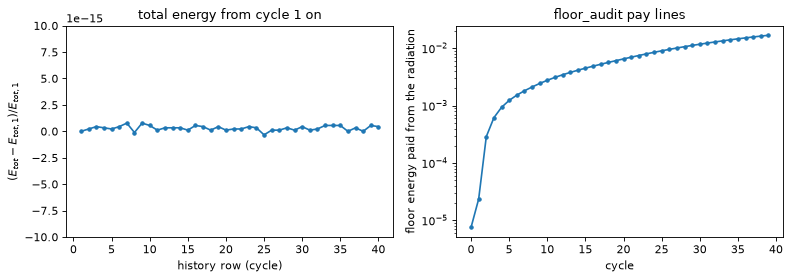

t = 0 -> 1 step of E_tot: 7.585042e-06;  initial floor energy (cycle 0 refresh): 7.585042e-06
PASS floor_pay   criterion {"max": {"dE": 1e-13}, "min": {"paid": 1e-06}, "equal": {"unpaid": 0.0, "warnings": 0}}


In [3]:
import re
d = os.path.join(WORK, TEST, 'run')
u = os.path.join(d, 'sp.user.hst')
e = nb.rt.hst_col(u, 'Eg') + nb.rt.hst_col(u, 'Er')
log = open(os.path.join(d, 'run.log')).read()
paid = [float(x) for x in re.findall(r'floor_audit cycle \d+ pay: paid (\S+)', log)]
init = float(re.search(r'floor_audit cycle 0 \[refresh\].*? floor_de (\S+)', log).group(1))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(range(1, len(e)), (e[1:] - e[1])/e[1], 'o-', ms=3)
ax[0].set(xlabel='history row (cycle)', ylabel=r'$(E_{tot} - E_{tot,1})/E_{tot,1}$', title='total energy from cycle 1 on', ylim=(-1e-14, 1e-14))
ax[1].semilogy(range(len(paid)), paid, 'o-', ms=3)
ax[1].set(xlabel='cycle', ylabel='floor energy paid from the radiation', title='floor_audit pay lines')
plt.tight_layout(); plt.show()
print('t = 0 -> 1 step of E_tot: %.6e;  initial floor energy (cycle 0 refresh): %.6e' % (e[0] - e[1], init))
_ = nb.verdict(TEST, res)